## Coffee Shop Sales: Data Analysis

### 1. Set up Spark and load data

In [19]:
import os

os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("CoffeeShopDataAnalysis")
    .master("local[2]")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)

print("Spark Version:", spark.version)

Spark Version: 4.2.0


In [20]:
file_path = r"D:\Projects\Coffee Shop Sales - Cluster Computing\Dataset\Coffee Shop Sales.csv"
df = spark.read.csv(
    file_path,
    header = True,
    inferSchema = True
)
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.show(5, truncate=False)

Total Rows: 149116
Total Columns: 11
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|transaction_id|transaction_date|transaction_time   |transaction_qty|store_id|store_location |product_id|unit_price|product_category  |product_type         |product_detail             |
+--------------+----------------+-------------------+---------------+--------+---------------+----------+----------+------------------+---------------------+---------------------------+
|1             |01-01-2023      |2026-10-20 07:06:11|2              |5       |Lower Manhattan|32        |3.0       |Coffee            |Gourmet brewed coffee|Ethiopia Rg                |
|2             |01-01-2023      |2026-10-20 07:08:56|2              |5       |Lower Manhattan|57        |3.1       |Tea               |Brewed Chai tea      |Spicy Eye Opener Chai Lg   |
|3             |01-01-2023      |

### 2. Revenue by product category

In [21]:
from pyspark.sql.functions import col, sum

df = df.withColumn(
    "revenue",
    col("transaction_qty") * col("unit_price")
)

category_revenue = (
    df.groupBy("product_category")
    .agg(sum("revenue").alias("total_revenue"))
    .orderBy(col("total_revenue").desc())
)

category_revenue.show(truncate=False)

+------------------+-----------------+
|product_category  |total_revenue    |
+------------------+-----------------+
|Coffee            |269952.4499999976|
|Tea               |196405.9500000037|
|Bakery            |82315.64000000006|
|Drinking Chocolate|72416.0          |
|Coffee beans      |40085.25000000005|
|Branded           |13607.0          |
|Loose Tea         |11213.59999999991|
|Flavours          |8408.800000000276|
|Packaged Chocolate|4407.639999999991|
+------------------+-----------------+



### 3. Revenue by store location

In [22]:
from pyspark.sql.functions import col, sum

store_revenue = (
    df.groupBy("store_location")
    .agg(sum("revenue").alias("total_revenue"))
    .orderBy(col("total_revenue").desc())
)

store_revenue.show(truncate=False)

+---------------+------------------+
|store_location |total_revenue     |
+---------------+------------------+
|Hell's Kitchen |236511.17000000307|
|Astoria        |232243.91000000044|
|Lower Manhattan|230057.2500000035 |
+---------------+------------------+



### 4. Sales by hour

In [23]:
from pyspark.sql.functions import hour, col, sum

df = df.withColumn(
    "hour",
    hour(col("transaction_time"))
)

hourly_sales = (
    df.groupBy("hour")
    .agg(sum("revenue").alias("total_revenue"))
    .orderBy("hour")
)

hourly_sales.show(24)

+----+------------------+
|hour|     total_revenue|
+----+------------------+
|   6| 21900.27000000004|
|   7| 63526.46999999974|
|   8| 82699.86999999937|
|   9| 85169.52999999939|
|  10|  88673.3899999993|
|  11| 46319.14000000006|
|  12|40192.790000000095|
|  13| 40367.45000000006|
|  14| 41304.74000000005|
|  15| 41733.10000000004|
|  16|41122.750000000015|
|  17| 40134.31000000004|
|  18| 34286.20000000007|
|  19|28446.680000000066|
|  20| 2935.639999999999|
+----+------------------+



### 5. Sales by day of week

In [24]:
from pyspark.sql.functions import (
    to_date, dayofweek, col, sum
)

# Convert the date string into a proper DateType
df = df.withColumn(
    "transaction_date",
    to_date(col("transaction_date"), "dd-MM-yyyy")
)

# Extract day of the week
df = df.withColumn(
    "day_of_week",
    dayofweek(col("transaction_date"))
)

# Calculate revenue for each weekday
daily_week_sales = (
    df.groupBy("day_of_week")
    .agg(sum("revenue").alias("total_revenue"))
    .orderBy("day_of_week")
)

daily_week_sales.show()

+-----------+------------------+
|day_of_week|     total_revenue|
+-----------+------------------+
|          1| 98330.30999999917|
|          2|101677.27999999931|
|          3| 99455.93999999887|
|          4|100313.53999999908|
|          5|100767.77999999901|
|          6| 101372.9999999992|
|          7|  96894.4799999992|
+-----------+------------------+



### 6. Correlation analysis

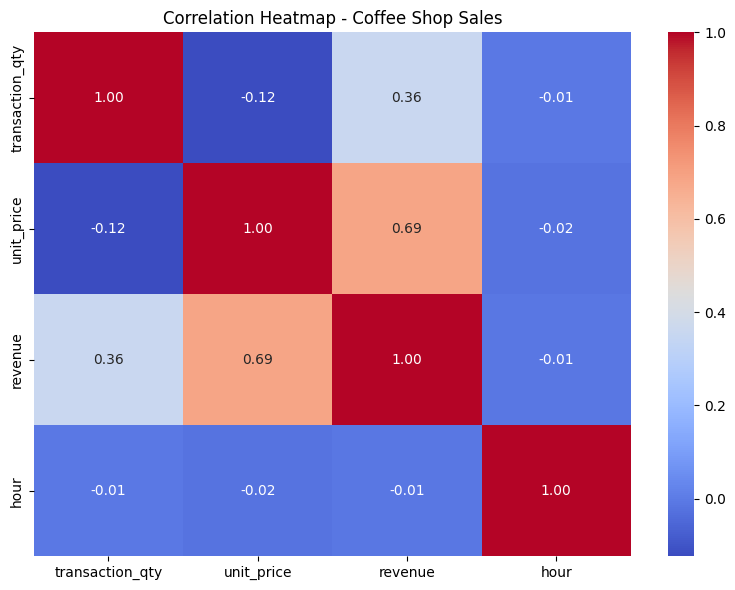

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = df.select(
    "transaction_qty",
    "unit_price",
    "revenue",
    "hour"
).toPandas()

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Coffee Shop Sales")
plt.tight_layout()
plt.show()